## Import bibliotek

In [1]:
from sklearn.datasets import load_iris
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# CZĘŚĆ PIERWSZA

## 1. Wczytanie danych

In [2]:
iris = load_iris()
X = iris.data
Y = iris.target
df = pd.DataFrame(X, columns=['Długość działki[cm]', 'Szerokość działki[cm]', 'Długość płatka[cm]', 'Szerokość płatka[cm]'])
df['gatunek'] = Y

## 2. Analiza danych

In [3]:
print(f"Liczba wierszy:{df.shape[0]}\n")
print(f"Liczba cech:{df.shape[1]}\n")
print(f"Podział na klasy:\n{df['gatunek'].value_counts()}\n")
print(f"Najmniejsze wartości każdej cechy:\n{df.iloc[:, :-1].min()}\n")
print(f"Największe wartości każdej cechy:\n{df.iloc[:, :-1].max()}\n")
print(f"Średnia każdej cechy:\n{df.iloc[:, :-1].mean()}\n")
print(f"Odchylenie standardowe każdej cechy:\n{df.iloc[:, :-1].std()}\n")

Liczba wierszy:150

Liczba cech:5

Podział na klasy:
gatunek
0    50
1    50
2    50
Name: count, dtype: int64

Najmniejsze wartości każdej cechy:
Długość działki[cm]      4.3
Szerokość działki[cm]    2.0
Długość płatka[cm]       1.0
Szerokość płatka[cm]     0.1
dtype: float64

Największe wartości każdej cechy:
Długość działki[cm]      7.9
Szerokość działki[cm]    4.4
Długość płatka[cm]       6.9
Szerokość płatka[cm]     2.5
dtype: float64

Średnia każdej cechy:
Długość działki[cm]      5.843333
Szerokość działki[cm]    3.057333
Długość płatka[cm]       3.758000
Szerokość płatka[cm]     1.199333
dtype: float64

Odchylenie standardowe każdej cechy:
Długość działki[cm]      0.828066
Szerokość działki[cm]    0.435866
Długość płatka[cm]       1.765298
Szerokość płatka[cm]     0.762238
dtype: float64



## 3. Normalizacja cech przy użyciu standaryzacji

In [4]:
X_mean = np.mean(X, axis= 0)
X_std = np.std(X, axis= 0)
X_stand = (X - X_mean) / X_std
print(f"Średnie kolumn po standaryzacji:\n{np.mean(X_stand, axis=0)}\n")
print(f"Odchylenia standardowe kolumn po standaryzacji:\n{np.std(X_stand, axis=0)}\n")

Średnie kolumn po standaryzacji:
[-1.69031455e-15 -1.84297022e-15 -1.69864123e-15 -1.40924309e-15]

Odchylenia standardowe kolumn po standaryzacji:
[1. 1. 1. 1.]



## 4. Zakodowanie etykiet klas w postaci one-hot

In [5]:
liczba_klas = len(np.unique(Y))
Y_one_hot = np.zeros((Y.size, liczba_klas))
Y_one_hot[np.arange(Y.size), Y] = 1
print(f"Zakodowane etykiety (pierwsze 5):\n{Y_one_hot[:5]}\n")

Zakodowane etykiety (pierwsze 5):
[[1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]
 [1. 0. 0.]]



## 5. Podział danych na zbiór uczący i testowy

In [6]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X_stand, Y_one_hot, test_size=0.3, stratify=Y_one_hot, random_state=42
)

## 6. Utworzenie sieci

In [7]:
np.random.seed(42)
wejscia = 4
ukryte = 5
wyjscia = 3
W1 = np.random.randn(wejscia, ukryte) * 0.1
b1 = np.zeros((1, ukryte))
W2 = np.random.randn(ukryte, wyjscia) * 0.1
b2 = np.zeros((1, wyjscia))

## 7. Implementacja funkcji aktywacji sigmoid i jej pochodnej

In [8]:
def sigmoid(X):
    return 1 / (1 + np.exp(-X))

def sigmoid_pochodna(wyjscie):
    # f'(x) = f(x) * (1 - f(x))
    return wyjscie * (1 - wyjscie)

## 8. Implementacja propagacji w przód

In [9]:
def forward_pass(X, W1, b1, W2, b2):
    z1 = np.dot(X, W1) + b1
    a1 = sigmoid(z1)
    z2 = np.dot(a1, W2) + b2
    a2 = sigmoid(z2)

    return a1, a2

## 9. Implementacja MSE i sprawdzenie wartości dla sieci z losowymi wagami

In [10]:
def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

a1_train, y_pred_train = forward_pass(X_train, W1, b1, W2, b2)
poczatkowy_koszt = mse(Y_train, y_pred_train)
print(f"Początkowy koszt dla losowych wag:\n{poczatkowy_koszt:.4f}")

Początkowy koszt dla losowych wag:
0.2501


# CZĘŚĆ DRUGA

## Punkty 11, 12, 13
- obliczenie błędu warstwy wyjściowej
- propagacja błędu do warstwy ukrytej
- obliczenie gradientow wag i biasów

In [11]:
def backward_pass(X, y_true, a_hid, y_pred, W_out):
    delta_out = (y_pred - y_true) * y_pred * (1 - y_pred)

    delta_hid = (delta_out @ W_out.T) * a_hid * (1 - a_hid)

    m = X.shape[0]

    dW_out = (a_hid.T @ delta_out) / m
    db_out = np.sum(delta_out) / m

    dW_hid = (X.T @ delta_hid) / m
    db_hid = np.sum(delta_hid) / m

    return dW_hid, db_hid, dW_out, db_out

## 14. Implementacja aktualizacji wag

In [12]:
def aktualizuj_wagi(W_hid, b_hid, W_out, b_out, dW_hid, db_hid, dW_out, db_out, eta):
    W_hid -= eta * dW_hid
    b_hid -= eta * db_hid
    W_out -= eta * dW_out
    b_out -= eta * db_out

    return W_hid, b_hid, W_out, b_out

## 15. Sprawdzenie poprawności gradientów metodą numeryczną

In [13]:
def gradient_checking(X, y, W_hid, b_hid, W_out, b_out, epsilon=1e-4):
    x_sample = X[0:1]
    y_sample = y[0:1]

    a_hid, y_pred = forward_pass(x_sample, W_hid, b_hid, W_out, b_out)

    delta_out = (y_pred - y_sample) * y_pred * (1 - y_pred)
    grad_analityczny = a_hid.T @ delta_out

    row, col = np.random.randint(0, W_out.shape[0]), np.random.randint(0, W_out.shape[1])
    wybrany_grad_anal = grad_analityczny[row, col]

    def koszt_do_testu(y_t, y_p):
        return 0.5 * np.sum((y_t - y_p) ** 2)

    W_out_plus = W_out.copy()
    W_out_plus[row, col] += epsilon
    _, y_pred_plus = forward_pass(x_sample, W_hid, b_hid, W_out_plus, b_out)
    J_plus = koszt_do_testu(y_sample, y_pred_plus)

    W_out_minus = W_out.copy()
    W_out_minus[row, col] -= epsilon
    _, y_pred_minus = forward_pass(x_sample, W_hid, b_hid, W_out_minus, b_out)
    J_minus = koszt_do_testu(y_sample, y_pred_minus)

    grad_numeryczny = (J_plus - J_minus) / (2 * epsilon)

    print(f"Test wagi W_out[{row}, {col}]:")
    print(f"Gradient analityczny: {wybrany_grad_anal:.8f}")
    print(f"Gradient numeryczny:  {grad_numeryczny:.8f}")
    print(f"Różnica: {abs(wybrany_grad_anal - grad_numeryczny):.8e}")


gradient_checking(X_train, Y_train, W1, b1, W2, b2)

Test wagi W_out[1, 1]:
Gradient analityczny: -0.06042959
Gradient numeryczny:  -0.06042959
Różnica: 1.21921431e-11


## 16. Test działania na problemie XOR

In [14]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y_xor = np.array([[0], [1], [1], [0]])

np.random.seed(42)
W1_xor = np.random.randn(2, 3) * 0.1
b1_xor = np.zeros((1, 3))
W2_xor = np.random.randn(3, 1) * 0.1
b2_xor = np.zeros((1, 1))

eta_xor = 0.5
epoki_xor = 10000

for epoka in range(epoki_xor):
    a1_x, a2_x = forward_pass(X_xor, W1_xor, b1_xor, W2_xor, b2_xor)
    dW1_x, db1_x, dW2_x, db2_x = backward_pass(X_xor, y_xor, a1_x, a2_x, W2_xor)
    W1_xor, b1_xor, W2_xor, b2_xor = aktualizuj_wagi(W1_xor, b1_xor, W2_xor, b2_xor, dW1_x, db1_x, dW2_x, db2_x, eta_xor)

blad_xor = mse(y_xor, a2_x)
print(f"Błąd XOR (MSE) po {epoki_xor} epokach: {blad_xor:.6f}")
print("Przewidywania sieci (oczekiwane: ~0, ~1, ~1, ~0):\n", np.round(a2_x, 4))

Błąd XOR (MSE) po 10000 epokach: 0.249996
Przewidywania sieci (oczekiwane: ~0, ~1, ~1, ~0):
 [[0.4989]
 [0.5005]
 [0.4995]
 [0.5011]]


## 17. Główna pętla

In [15]:
eta_iris = 0.1
epoki_iris = 5000
historia_kosztu = []

for epoka in range(epoki_iris):
    a_hid, y_pred = forward_pass(X_train, W1, b1, W2, b2)

    koszt = mse(Y_train, y_pred)
    historia_kosztu.append(koszt)

    dW_hid, db_hid, dW_out, db_out = backward_pass(X_train, Y_train, a_hid, y_pred, W2)

    W1, b1, W2, b2 = aktualizuj_wagi(W1, b1, W2, b2, dW_hid, db_hid, dW_out, db_out, eta_iris)

    if epoka % 1000 == 0:
        print(f"Epoka {epoka:4d} | Błąd MSE: {koszt:.4f}")

Epoka    0 | Błąd MSE: 0.2501
Epoka 1000 | Błąd MSE: 0.1227
Epoka 2000 | Błąd MSE: 0.1031
Epoka 3000 | Błąd MSE: 0.0847
Epoka 4000 | Błąd MSE: 0.0640


## Wykres spadku błędu

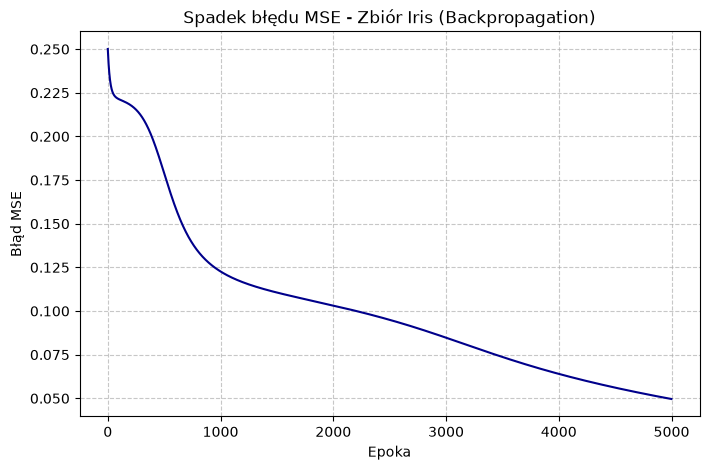

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(historia_kosztu, color='darkblue')
plt.title("Spadek błędu MSE - Zbiór Iris (Backpropagation)")
plt.xlabel("Epoka")
plt.ylabel("Błąd MSE")
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()